# 09 · Power and planning sample size

Power is the probability that a specified test will detect a specified effect under a specified design. Planning sample size means choosing the precision and detection capability needed before collecting data, while acknowledging uncertainty in the planning assumptions.

```mermaid
flowchart LR
    A[Choose meaningful effect] --> B[Specify variability and design]
    B --> C[Set alpha and desired power]
    C --> D[Solve for sample size]
    D --> E[Round and allow for losses]
    E --> F[Check sensitivity and simulate]
```

**Learning route:** error rates → sampling separation → effect size → power calculation → sensitivity. Prerequisites: [t-tests](../08_T-test_for_Testing_the_Differences/08_T-test_for_Testing_the_Differences.md).

## 1. Power is conditional, not a guarantee

For a rejection rule $R$ and true effect $\Delta$, define

$$\operatorname{Power}(\Delta)=P_{\Delta}(R),\qquad
\beta(\Delta)=1-\operatorname{Power}(\Delta).$$

At a nonzero alternative, rejection is a correct detection, also called a true positive. At the null, the rejection probability is the test's size, bounded by its level $\alpha$ when the test is valid. Thus a power curve can be defined at zero too, but that point represents false-positive probability, not useful detection.

An 80%-power design at an effect of two minutes means that, under that effect and the other assumptions, about 80% of repeated studies reject. It does not mean an 80% chance that the treatment works, that the observed result will be correct, or that every nonzero effect will be detected.

## 2. Why more independent observations help

For independent groups with common SD $\sigma$ and equal size $n$ per group, the difference in sample means has

$$E[\bar X_B-\bar X_A]=\Delta,\qquad
SE=\sigma\sqrt{2/n}.$$

The null sampling distribution is centered at zero. Under a positive alternative it is centered at $\Delta$. Increasing $n$ narrows both distributions while their centers stay the same. More of the alternative distribution then lies beyond a preplanned null cutoff.

For a known-SD normal test, let $\lambda=\Delta/[\sigma\sqrt{2/n}]$. The standardized statistic has distribution $N(\lambda,1)$ under the alternative, while the two-sided rejection region is $|Z|>z_{1-\alpha/2}$. Power is

$$\Phi(-z_{1-\alpha/2}-\lambda)
+1-\Phi(z_{1-\alpha/2}-\lambda).$$

![Null and alternative sampling distributions with rejection regions](figure/power_geometry.png)

**Notebook setup.** Run all cells from top to bottom. Figures are saved in this chapter's `figure/` folder. Restart the kernel and run all after changing a simulation. See the repository README for installation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

# Works when Jupyter starts in either this chapter or the repository root.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "scripts" / "build_notebooks.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the cloned course repository.")
FIGURE_DIR = ROOT / '09_Power_and_Power_Analysis' / "figure"
FIGURE_DIR.mkdir(exist_ok=True)
plt.rcParams.update({
    "figure.figsize": (9, 4.8), "figure.dpi": 110,
    "font.size": 11, "axes.titlesize": 14, "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#087E8B", "#D55E00", "#7251A2", "#4477AA"]),
    "savefig.facecolor": "white", "axes.facecolor": "#FAFBFC",
})
TEAL, ORANGE, PURPLE = "#087E8B", "#D55E00", "#7251A2"

def save_figure(fig, name):
    """Save the exact figure used by Markdown and display it in the notebook."""
    fig.savefig(FIGURE_DIR / f"{name}.png", dpi=180, bbox_inches="tight")
    fig.savefig(FIGURE_DIR / f"{name}.svg", bbox_inches="tight")
    display(fig)
    plt.close(fig)

print("All datasets in this notebook are synthetic teaching examples.")


All datasets in this notebook are synthetic teaching examples.


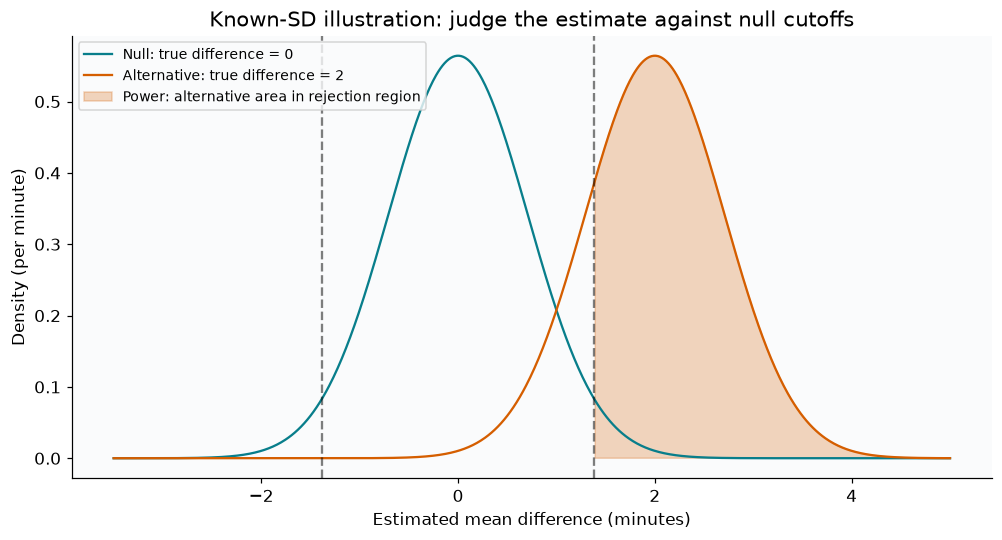

In [2]:
alpha,n,sigma,delta = .05,64,4,2
se = sigma*np.sqrt(2/n)
critical = stats.norm.ppf(1-alpha/2)*se
grid = np.linspace(-3.5,5,800)
null_density = stats.norm.pdf(grid,0,se)
alt_density = stats.norm.pdf(grid,delta,se)
reject = np.abs(grid)>critical
fig, ax = plt.subplots(layout="constrained")
ax.plot(grid,null_density,label="Null: true difference = 0")
ax.plot(grid,alt_density,label="Alternative: true difference = 2")
ax.fill_between(grid,alt_density,where=reject,color=ORANGE,alpha=.25,label="Power: alternative area in rejection region")
for boundary in [-critical,critical]: ax.axvline(boundary,color="black",ls="--",alpha=.5)
ax.set(xlabel="Estimated mean difference (minutes)",ylabel="Density (per minute)",title="Known-SD illustration: judge the estimate against null cutoffs")
ax.legend(fontsize=9)
save_figure(fig,"power_geometry")

The graph uses the **distribution of a mean difference**, not the overlap of individual observations. Individual distributions may overlap extensively while a large study estimates their means precisely. More dependent repetitions do not necessarily provide the same gain as more independent units.

## 3. Choose an effect worth detecting

Suppose a workshop considers a process change worthwhile if it saves at least **two minutes** on average. Prior process knowledge suggests a common SD of **four minutes**. For equal-variance independent groups, the standardized effect magnitude is

$$d=\frac{|\Delta|}{\sigma}=\frac24=0.5.$$

This is a planning value, not an effect discovered in the current study. Use the smallest effect of practical interest, informed by the decision and credible prior data. Choosing an optimistic pilot estimate can badly underpower a later study. Generic labels such as “small” and “large” do not decide what matters for a particular workshop.

A signed Cohen's $d$ is useful when reporting direction. The magnitude is sufficient for a two-sided power calculation. Specify the denominator convention; paired standardized changes and independent-group pooled-SD effects are not interchangeable.

## 4. Calculate sample size for the planned test

An approximate known-SD, balanced, two-sided design uses

$$n\approx\frac{2(z_{1-\alpha/2}+z_{1-\beta})^2}{d^2}.$$

At $\alpha=0.05$, power 0.80, and $d=0.5$, this is about 62.79 observations **per group**, before rounding. The expression approximates power by emphasizing the main rejection tail under a directional effect; it is useful for intuition and initial planning, not a replacement for the appropriate test calculation.

For the pooled two-sample t-test, use the noncentral t distribution. With equal group sizes,

$$df=2n-2,\qquad \lambda=d\sqrt{n/2},\qquad
c=t_{1-\alpha/2,df},$$

$$\operatorname{Power}=P(t_{df,\lambda}<-c)+P(t_{df,\lambda}>c).$$

The cutoff comes from the **central** null t distribution, while rejection probability under the alternative comes from the **noncentral** distribution. The notebook solves this numerically with statsmodels and independently checks the result with SciPy's noncentral t CDF and survival function.

The result is about **63.77 per group**. Round up to **64 per group, 128 total**, and recompute the achieved power, about 0.8015. Rounding down would miss the target. If 20% of recruited units are expected to be unusable for a reason accounted for in the design, start with $\lceil64/(1-0.20)\rceil=80$ per group. This numerical allowance does not solve bias from outcome-dependent missingness.

In [3]:
from statsmodels.stats.power import TTestIndPower
from math import ceil
planner = TTestIndPower()
d,target_power,alpha = .5,.8,.05
n_approx = 2*(stats.norm.ppf(1-alpha/2)+stats.norm.ppf(target_power))**2/d**2
n_continuous = planner.solve_power(effect_size=d,alpha=alpha,power=target_power,ratio=1,alternative="two-sided")
n_per_group = ceil(n_continuous)
achieved = planner.power(effect_size=d,nobs1=n_per_group,alpha=alpha,ratio=1,alternative="two-sided")
df = 2*n_per_group-2
noncentrality = d*np.sqrt(n_per_group/2)
cutoff = stats.t.ppf(1-alpha/2,df)
independent_power = stats.nct.cdf(-cutoff,df,noncentrality)+stats.nct.sf(cutoff,df,noncentrality)
assert n_per_group==64 and np.isclose(achieved,independent_power)
assert achieved>=target_power and planner.power(d,n_per_group-1,alpha,ratio=1)<target_power
print(f"Normal approximation: {n_approx:.3f}; t-based solution: {n_continuous:.3f}")
print(f"Round up: {n_per_group} per group, {2*n_per_group} total; power={achieved:.5f}")
print("Recruitment with 20% loss:",ceil(n_per_group/.8),"per group")

Normal approximation: 62.791; t-based solution: 63.766
Round up: 64 per group, 128 total; power=0.80146
Recruitment with 20% loss: 80 per group


This calculation assumes independent observations, common normal error variance, equal allocation, a two-sided pooled test, and one planned comparison. A Welch design with unequal variances, a paired design, a cluster trial, or a multiple-testing procedure needs a matching power calculation or simulation.

## 5. A sensitivity analysis is part of the answer

Planning inputs are uncertain. Calculate several plausible effect sizes and SDs, not just one convenient number. The notebook displays sample sizes for several $d$ values and compares 80% with 90% desired power.

![Power curves for several standardized effects](figure/power_curves.png)

,d,desired_power,n_per_group,total_n
0,0.3,0.8,176,352
1,0.3,0.9,235,470
2,0.4,0.8,100,200
3,0.4,0.9,133,266
4,0.5,0.8,64,128
5,0.5,0.9,86,172
6,0.6,0.8,45,90
7,0.6,0.9,60,120
8,0.8,0.8,26,52
9,0.8,0.9,34,68


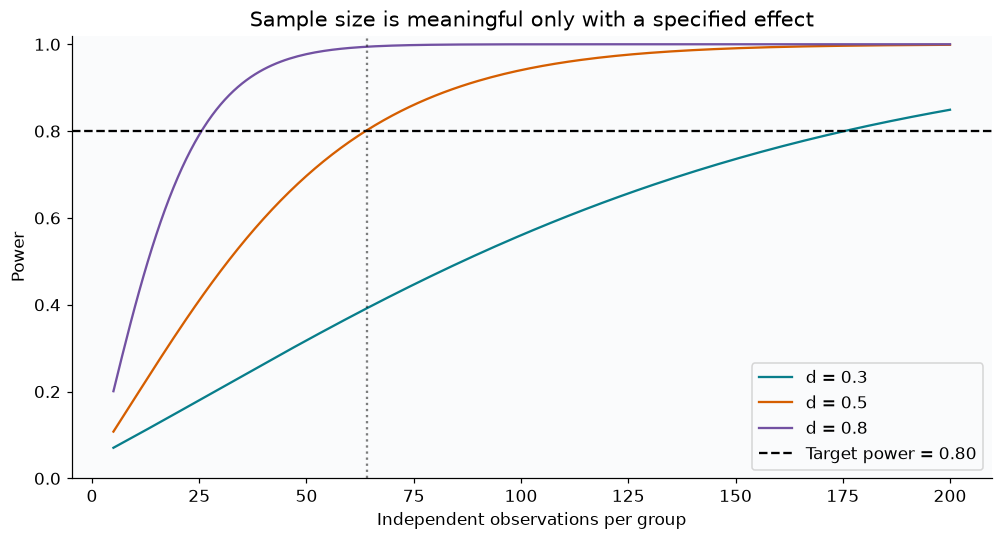

In [4]:
rows = []
for effect in [.3,.4,.5,.6,.8]:
    for desired in [.8,.9]:
        needed = ceil(planner.solve_power(effect_size=effect,power=desired,alpha=.05,ratio=1))
        rows.append([effect,desired,needed,2*needed])
display(pd.DataFrame(rows,columns=["d","desired_power","n_per_group","total_n"]))
sizes = np.arange(5,201)
fig, ax = plt.subplots(layout="constrained")
for effect in [.3,.5,.8]:
    ax.plot(sizes,planner.power(effect_size=effect,nobs1=sizes,alpha=.05,ratio=1),label=f"d = {effect}")
ax.axhline(.8,ls="--",color="black",label="Target power = 0.80")
ax.axvline(64,ls=":",color="black",alpha=.5)
ax.set(xlabel="Independent observations per group",ylabel="Power",ylim=(0,1.02),title="Sample size is meaningful only with a specified effect")
ax.legend()
save_figure(fig,"power_curves")

For the same test and allocation, larger effects and lower variability generally improve power. Larger sample size improves precision. A smaller $\alpha$ makes rejection harder and reduces power at fixed $n$; maintaining power then needs more information. These are design tradeoffs, not reasons to relax the significance threshold after seeing a result.

The approximate formula shows why detecting half the effect requires about four times the sample size when SD is unchanged. Improving measurement reliability or using justified pairing/blocking can be valuable because reducing noise also reduces the information required. If cluster sizes are $m$ and within-cluster correlation is $\rho$, the rough design effect $1+(m-1)\rho$ illustrates why many measurements from few clusters can be inefficient; actual cluster designs need more careful planning.

## 6. Verify power by simulating the full procedure

The notebook simulates 10,000 independent studies under $\Delta=2$, $\sigma=4$, and $n=64$ per group. It performs the same two-sided pooled t-test that the planning calculation assumes. The rejection fraction should be near the theoretical power, within simulation error.

For $B$ repetitions and estimated power $\hat\pi$, the Monte Carlo SE is $\sqrt{\hat\pi(1-\hat\pi)/B}$. At 0.80 with 10,000 repetitions, this is about 0.004. Deviations of a few thousandths are ordinary simulation noise. This check does not validate the realism of the normal or common-variance assumptions.

In [5]:
rng = np.random.default_rng(909)
repetitions = 10000
group_a = rng.normal(20,4,(repetitions,64))
group_b = rng.normal(22,4,(repetitions,64))
tests = stats.ttest_ind(group_b,group_a,axis=1,equal_var=True)
estimated_power = np.mean(tests.pvalue<=.05)
mc_se = np.sqrt(estimated_power*(1-estimated_power)/repetitions)
print(f"Monte Carlo power={estimated_power:.4f}, SE={mc_se:.4f}, theoretical={achieved:.4f}")
assert abs(estimated_power-achieved)<5*mc_se

Monte Carlo power=0.8002, SE=0.0040, theoretical=0.8015


Simulation becomes especially useful when the real analysis includes unequal variances, clustering, missing values, or complicated decision rules. Generate data from explicit plausible scenarios and run the **entire planned analysis**, including any stopping or selection procedure.

## 7. Avoid observed-power reasoning

After a study, substituting the observed effect into the planning formula and calling the resulting number “observed power” adds little beyond the p-value and can be misleading. The observed effect is noisy, especially in small studies. Report its estimate and interval; discuss which scientifically meaningful effects the data constrain.

For a new study, revisit power using a defensible effect range and variability assumptions. A previous nonsignificant result is neither proof of zero effect nor a license to add observations until significance appears. A valid sequential design can allow repeated looks, but it must calibrate the stopping rule.

## 8. Practice

1. A meaningful change is 3 units and the common SD is 6. What standardized effect should a balanced independent-group planner use?
2. Approximately how does required $n$ change if the target effect halves while SD, power, and $\alpha$ stay fixed?
3. A calculator returns 87.2 observations per group. What is the minimum rounded total? With 15% expected loss, how many should initially be recruited per group?
4. Does 90% power mean that a significant result has a 90% chance of being true?
5. Why should a paired study not simply use an independent-group sample-size result?

## 9. Worked answers

1. $d=3/6=0.5$. Keep the 3-unit practical meaning in the report as well.
2. About four times as many per group, because the approximation is proportional to $1/d^2$.
3. Round to 88 per group, 176 total. Inflate to $\lceil88/0.85\rceil=104$ per group, or 208 initially, subject to the missingness assumptions.
4. No. Power conditions on a specified alternative being true. It is not a posterior probability for a discovered result.
5. Its information comes from within-pair differences and their SD, including covariance. Its independent unit is a pair; its test and degrees of freedom differ.

In [6]:
assert 3/6==.5
print("Rounded study total:",2*ceil(87.2))
print("Initial recruitment per group:",ceil(ceil(87.2)/.85))

Rounded study total: 176
Initial recruitment per group: 104


## References and next step

Reading connection: Starmer (2026), Chapter 9, [SQ](../Reference.md#sq-statquest). Power implementation: [statsmodels TTestIndPower](https://www.statsmodels.org/stable/generated/statsmodels.stats.power.TTestIndPower.html); noncentral reference: [SciPy nct](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.nct.html). The planning scenario and sensitivity analysis are original.

Next: [10 · P-value pitfalls](../10_P-Values_Pitfalls/10_P-Values_Pitfalls.md).